# OLS Signal Trading

This will be a stand in repo for testing the signal trading for the OLS signal standpoint

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Global Variables and Data

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
src_path  = os.path.join(repo_path, "src")
data_path = os.path.join(repo_path, "data")

In [3]:
sys.path.append(src_path)
from SignalFitter import SignalFitter

In [4]:
trend_path = os.path.join(data_path, "GenericTrendSignal.parquet")
df_data    = (pd
    .read_parquet(path = trend_path, engine = "pyarrow")
    .assign(signal_name = lambda x: x.Ticker + "_" + x.window.astype(str)))

In [5]:
df_data.head(5)

,Ticker,Date,lag_signal,signal,window,rtn,signal_name
0,AGG,2003-10-01,NaN,-0.121794,8,-0.000486,AGG_8
1,AGG,2003-10-02,-0.121794,-0.177490,8,-0.001559,AGG_8
2,AGG,2003-10-03,-0.177490,-0.403561,8,-0.007219,AGG_8
3,AGG,2003-10-06,-0.403561,-0.250314,8,0.001474,AGG_8
4,AGG,2003-10-07,-0.250314,-0.349705,8,-0.003435,AGG_8


In [6]:
print(src_path)

A:\GitHub\SignalTrader\src


# OLS Models

First start by comparing in-sample model and since we care about the relationship contemporaneously and lagged we fit both lagged and unlagged

In [7]:
signal_fitter = SignalFitter(rtn_col = "rtn", group_col = "signal_name", date_col = "Date")

lag_full_sample        = signal_fitter.fit_full_sample(df_data, signal_col = "lag_signal")
lag_full_sample_params = signal_fitter.get_params(lag_full_sample)

full_sample        = signal_fitter.fit_full_sample(df_data, signal_col = "signal")
full_sample_params = signal_fitter.get_params(full_sample)

Then we are supposed to get the parameters

In [8]:
df_nolag = (full_sample_params
    .loc[lambda x: x.variable == "signal"]
    [["signal_name", "params"]]
    .rename(columns = {"params": "no_lag"}))

In [9]:
df_lag = (lag_full_sample_params
    .loc[lambda x: x.variable == "lag_signal"]
    [["signal_name", "params"]]
    .rename(columns = {"params": "lag"}))

In [10]:
(df_lag
    .merge(right = df_nolag, how = "inner", on = ["signal_name"])
    .assign(
        ticker = lambda x: x.signal_name.str.split("_").str[0],
        window = lambda x: x.signal_name.str.split("_").str[-1])
    .drop(columns = ["signal_name"])
    .melt(id_vars = ["window", "ticker"])
    .pivot(index = "ticker", columns = ["variable", "window"], values = "value"))

variable       lag                                            no_lag  \
window         128        16        32        64         8       128   
ticker                                                                 
AGG       0.138492 -0.078401 -0.019135  0.058155 -0.105346  1.485321   
BND       0.156577 -0.056749 -0.001948  0.078650 -0.076242  1.374113   
EMB       0.124280  0.229433  0.211609  0.173182  0.222166  0.735062   
GLD       0.002545  0.027060  0.019651  0.011897  0.028260  0.903566   
IEFA      0.075874 -0.055243 -0.082293 -0.018238 -0.017556  0.594331   
IEMG     -0.100283 -0.050734 -0.074002 -0.105742 -0.034463  0.893687   
IWF      -0.033815 -0.108028 -0.074705 -0.037010 -0.109185  0.174830   
IYY      -0.052145 -0.138800 -0.153156 -0.133827 -0.110264  1.291291   
QQQ      -0.108389 -0.151562 -0.171263 -0.172148 -0.121852  0.890467   
SPY      -0.150177 -0.190236 -0.219032 -0.216259 -0.149758  1.355489   
VEA      -0.111754 -0.106957 -0.140591 -0.138080 -0.073089  1.157768   
VWO      -0.022380 -0.081807 -0.059037 -0.024191 -0.081355  0.459412   

variable                                          
window          16        32        64         8  
ticker                                            
AGG       1.778324  1.707630  1.605986  1.768643  
BND       1.706291  1.621254  1.507334  1.714629  
EMB       1.390381  1.286144  1.083491  1.429664  
GLD       1.599222  1.502721  1.300617  1.627028  
IEFA      1.737230  1.592595  1.137706  1.710652  
IEMG      1.605349  1.520993  1.308669  1.610923  
IWF       1.466778  1.074002  0.547047  1.611386  
IYY       1.703880  1.614404  1.474628  1.710318  
QQQ       1.559814  1.431039  1.224102  1.606736  
SPY       1.717518  1.637533  1.512674  1.716097  
VEA       1.759559  1.716628  1.538742  1.717978  
VWO       1.584167  1.374863  0.959346  1.632818

Now we get the train-test model the idea is that we use the ratio which splits time series by ratio

In [11]:
train_test        = signal_fitter.fit_train_test_ratio(df_data, "lag_signal")
train_test_params = signal_fitter.get_params(train_test)

We then get the parameters from the train-test to the full-sample

In [12]:
df_train_params = (train_test_params
    .loc[lambda x: x.variable == "lag_signal"]
    [["signal_name", "variable", "params"]]
    .drop(columns = ["variable"])
    .rename(columns = {"params": "train_sample"}))

In [13]:
display(df_lag
    .merge(right = df_train_params, how = "inner", on = ["signal_name"])
    .assign(
        ticker = lambda x: x.signal_name.str.split("_").str[0],
        window = lambda x: x.signal_name.str.split("_").str[1])
    .drop(columns = ["signal_name"])
    .melt(id_vars = ["ticker", "window"])
    .replace({"lag": "full_sample"})
    .pivot(index = "ticker", columns = ["variable", "window"], values = "value"))

variable full_sample                                         train_sample  \
window           128        16        32        64         8          128   
ticker                                                                      
AGG         0.138492 -0.078401 -0.019135  0.058155 -0.105346    -0.020875   
BND         0.156577 -0.056749 -0.001948  0.078650 -0.076242     0.063484   
EMB         0.124280  0.229433  0.211609  0.173182  0.222166     0.111083   
GLD         0.002545  0.027060  0.019651  0.011897  0.028260     0.009581   
IEFA        0.075874 -0.055243 -0.082293 -0.018238 -0.017556     0.098908   
IEMG       -0.100283 -0.050734 -0.074002 -0.105742 -0.034463    -0.105450   
IWF        -0.033815 -0.108028 -0.074705 -0.037010 -0.109185    -0.021503   
IYY        -0.052145 -0.138800 -0.153156 -0.133827 -0.110264     0.015120   
QQQ        -0.108389 -0.151562 -0.171263 -0.172148 -0.121852    -0.053495   
SPY        -0.150177 -0.190236 -0.219032 -0.216259 -0.149758    -0.076551   
VEA        -0.111754 -0.106957 -0.140591 -0.138080 -0.073089    -0.101690   
VWO        -0.022380 -0.081807 -0.059037 -0.024191 -0.081355    -0.009536   

variable                                          
window          16        32        64         8  
ticker                                            
AGG      -0.137371 -0.091503 -0.040315 -0.157202  
BND      -0.094401 -0.064249  0.003225 -0.092587  
EMB       0.293517  0.260123  0.192432  0.293143  
GLD       0.044972  0.042518  0.031369  0.034093  
IEFA     -0.048162 -0.062852  0.013754 -0.014859  
IEMG     -0.005809 -0.015129 -0.067067 -0.011360  
IWF      -0.108531 -0.057353 -0.014987 -0.118967  
IYY      -0.154414 -0.149710 -0.095964 -0.131903  
QQQ      -0.150090 -0.159000 -0.136110 -0.122687  
SPY      -0.216774 -0.228651 -0.185779 -0.179136  
VEA      -0.090894 -0.110544 -0.110535 -0.070118  
VWO      -0.062407 -0.024080  0.010062 -0.079465

The same steps for this except use the in-sample and out-of-sample model for the lagged signal that we predict

In [24]:
expanding_model = signal_fitter.fit_expanding(df_data, "lag_signal")
bt_full_sample  = signal_fitter.backtest_fitted(lag_full_sample)
bt_train_test   = signal_fitter.backtest_fitted(train_test)
bt_expanding    = signal_fitter.backtest_fitted(expanding_model)

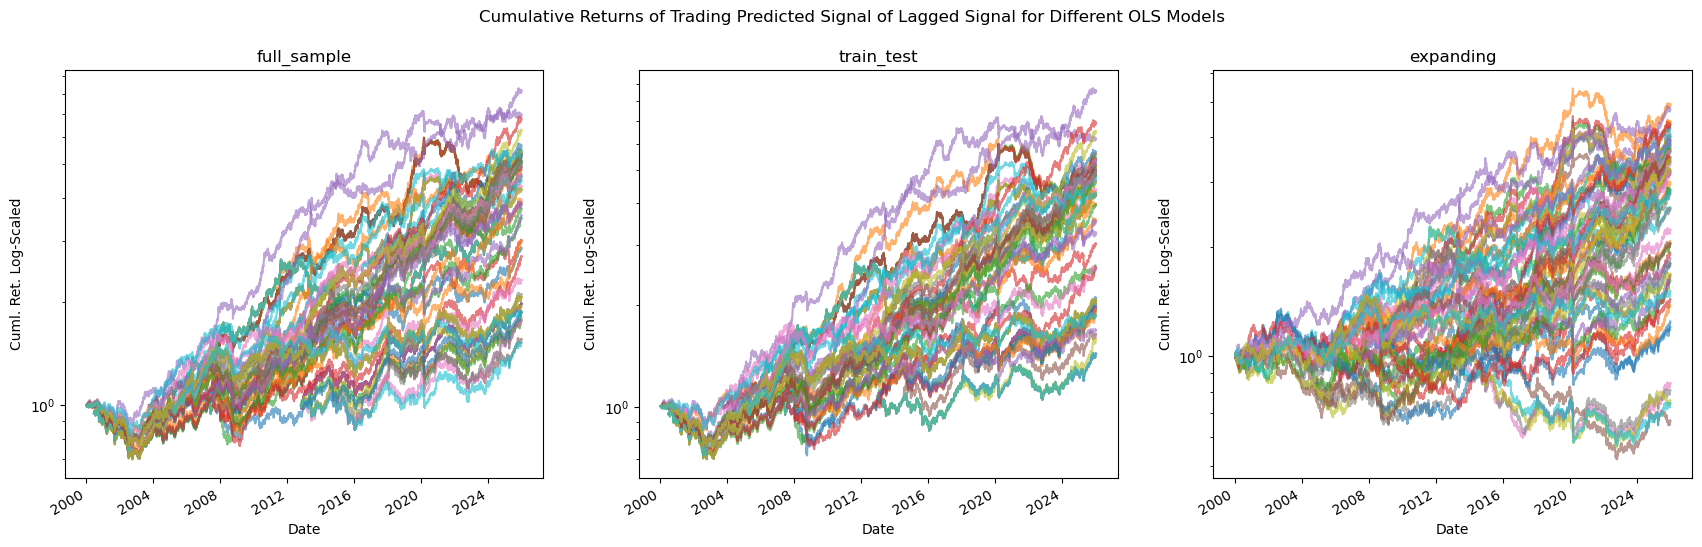

In [26]:
models = {
    "full_sample": bt_full_sample,
    "train_test" : bt_train_test,
    "expanding"  : bt_expanding}

fig, axes = plt.subplots(ncols = len(models.keys()), figsize = (len(models.keys()) * 7, 6))
for key, ax in zip(models.keys(), axes.flatten()):

    (models
        [key]
        .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
        .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
        .apply(lambda x: np.cumprod(1 + x))
        .plot(
            logy   = True, 
            legend = False,
            ax     = ax,
            alpha  = 0.6,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = key))

fig.suptitle("Cumulative Returns of Trading Predicted Signal of Lagged Signal for Different OLS Models")
plt.show()

In [17]:
df_port = pd.concat([(models
    [key]
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .mean(axis = 1)
    .to_frame(name = "port_rtn")
    .assign(model = key))
    for key in models.keys()])

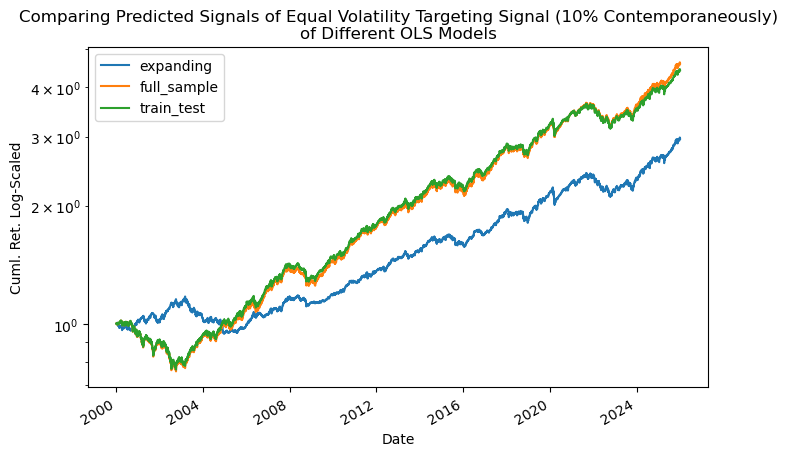

In [27]:
(df_port
    .reset_index()
    .rename(columns = {"model": ""})
    .pivot(index = "Date", columns = "", values = "port_rtn")
    .apply(lambda x: np.cumprod(1 + x))
    .plot(
        figsize = (8,5),
        logy    = True,
        ylabel  = "Cuml. Ret. Log-Scaled",
        title   = "Comparing Predicted Signals of Equal Volatility Targeting Signal (10% Contemporaneously)\nof Different OLS Models"))
plt.show()

Now do this for the residuals

In [28]:
expanding_model = signal_fitter.fit_expanding(df_data, "signal")
bt_full_sample  = signal_fitter.backtest_residual(lag_full_sample)
bt_train_test   = signal_fitter.backtest_residual(train_test)
bt_expanding    = signal_fitter.backtest_residual(expanding_model)

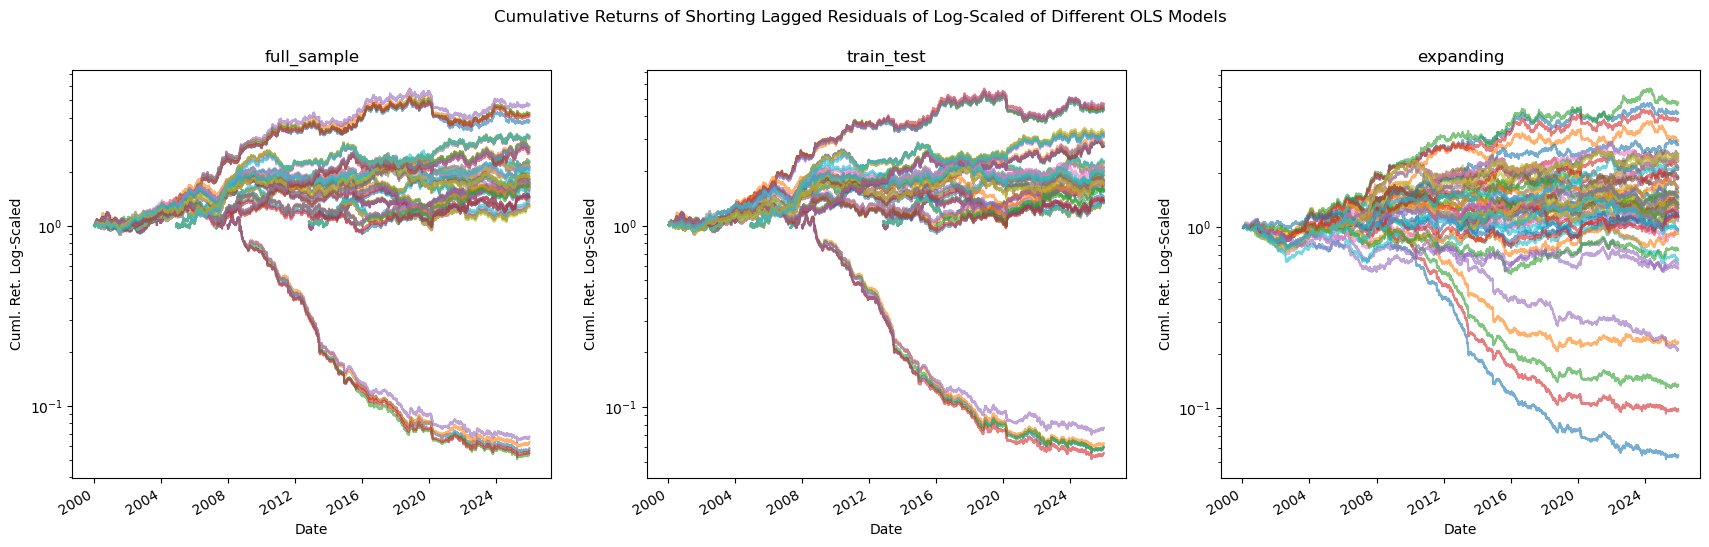

In [29]:
models = {
    "full_sample": bt_full_sample,
    "train_test" : bt_train_test,
    "expanding"  : bt_expanding}

fig, axes = plt.subplots(ncols = len(models.keys()), figsize = (len(models.keys()) * 7, 6))
for key, ax in zip(models.keys(), axes.flatten()):

    (models
        [key]
        .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
        .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
        .apply(lambda x: np.cumprod(1 + x))
        .plot(
            logy   = True, 
            legend = False,
            ax     = ax,
            alpha  = 0.6,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = key))

fig.suptitle("Cumulative Returns of Shorting Lagged Residuals of Log-Scaled of Different OLS Models")
plt.show()

In [35]:
df_port = pd.concat([(models
    [key]
    .pivot(index = "Date", columns = "signal_name", values = "signal_rtn")
    .apply(lambda x: x * (0.1 / (x.ewm(span = 100, adjust = False).std() * np.sqrt(252))))
    .apply(lambda x: np.where(np.abs(x) > 0.5, np.nan, x))
    .mean(axis = 1)
    .to_frame(name = "port_rtn")
    .assign(model = key))
    for key in models.keys()])

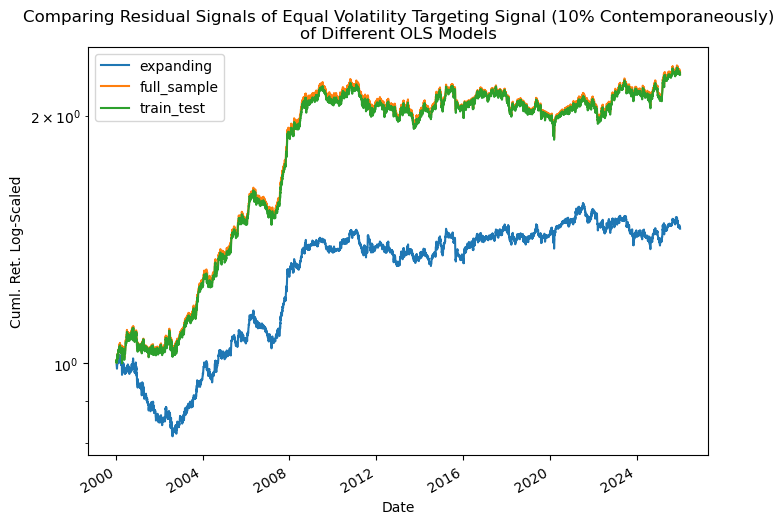

In [41]:
(df_port
    .reset_index()
    .rename(columns = {"model": ""})
    .pivot(index = "Date", columns = "", values = "port_rtn")
    .apply(lambda x: np.cumprod(1 + x))
    .plot(
        figsize = (8,6),
        logy    = True,
        ylabel  = "Cuml. Ret. Log-Scaled",
        title   = "Comparing Residual Signals of Equal Volatility Targeting Signal (10% Contemporaneously)\nof Different OLS Models"))
plt.show()